# Variational Inference for GARCH-Family Models
### Bayesian volatility estimation: QML vs. MCMC vs. Variational Inference

**Course:** Time Series Econometrics, Fordham University
**Reference paper:** Magris, M. & Iosifidis, A. (2023). *Variational Inference for GARCH-family Models*. arXiv:2310.03435

**Research question.** Can Gaussian Variational Inference (VI) give Bayesian GARCH estimates and forecasts that are as good as
Markov Chain Monte Carlo (MCMC) and Quasi-Maximum Likelihood (QML), and what does it cost to compute them?

**Design (follows the paper's Microsoft case study):**

| Item | Choice |
|---|---|
| Data | Daily close-to-close log returns, Microsoft (MSFT), 1 Jan 2018 – 30 Jun 2023 (1,383 trading days) |
| Split | Chronological 75% train / 25% test |
| Model | GARCH(1,1) with zero mean, Gaussian innovations (Student-t as an extension) |
| Benchmarks | QML (frequentist) and Random-Walk Metropolis MCMC (Bayesian "gold standard") |
| VI methods | (i) **BBVI**, the paper's black-box score-function algorithm (diagonal covariance); (ii) **Full-covariance Gaussian VI** in PyTorch using the reparameterisation trick |
| Metrics | NLL, RMSE, MAD and QLIK on train and test sets; posterior means and standard deviations; run time |
| Scale check | Repeat QML / MCMC / BBVI across the Dow Jones 30 constituents of the S&P 500 (a smaller version of the paper's Table I) |
| Note on data | Yahoo Finance is free and reproducible. WRDS/CRSP would give the same daily close-to-close returns and needs institutional login, so it is not required here |

**Notebook roadmap:** 1 Setup → 2 Data collection → 3 Data cleaning → 4 Exploratory analysis → 5 Model & transforms →
6 QML → 7 MCMC → 8 BBVI → 9 Full-covariance VI → 10 Comparison → 11 Volatility forecasts with uncertainty →
12 Student-t extension → 13 Multi-stock experiment → 14 Conclusions

## 1. Setup

Install any missing packages (Google Colab already ships with `numpy`, `pandas`, `torch`, `numba` and `matplotlib`).

In [1]:
import importlib.util, subprocess, sys

for pkg in ["arch", "yfinance", "numba", "statsmodels"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yfinance as yf
from numba import njit
from scipy import stats
from scipy.optimize import minimize
from scipy.special import expit
from statsmodels.tools.numdiff import approx_hess
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf
from arch import arch_model

In [3]:
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_default_dtype(torch.float64)

# Colours match the presentation slides
TEAL, GOLD, LIGHT, DARK, GREY = "#2A6F8A", "#D08F27", "#5FB3C6", "#063A47", "#8C8C8C"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # Save the current figure (used for the presentation slides).
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200, bbox_inches="tight")

## 2. Data Collection

We use the **same asset and window as the paper's case study** (Microsoft, 1 Jan 2018 – 30 Jun 2023) so that our estimates
can be checked directly against the paper's Table II. Prices come from Yahoo Finance (`yfinance`), adjusted for splits and dividends.

A local copy is saved to `data/` so that the results can be reproduced even if Yahoo revises its history.

In [4]:
TICKER, START, END = "MSFT", "2018-01-01", "2023-07-01"   # END is exclusive in yfinance
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

In [5]:
def load_prices(ticker, start=START, end=END):
    # Load adjusted close prices from the local cache, or download them from Yahoo Finance.
    path = os.path.join(DATA_DIR, f"{ticker}.csv")
    if os.path.exists(path):
        return pd.read_csv(path, index_col=0, parse_dates=True)
    df = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.droplevel(1)
    df.to_csv(path)
    return df

In [6]:
raw = load_prices(TICKER)
raw.head()

/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/private/tmp/claude-501/-User

Price,Close,High,Low,Open,Volume
Date,,,,,
2018-01-02,78.552010,78.881024,78.140745,78.716517,22483800
2018-01-03,78.917587,79.063819,78.570298,78.652548,26061400
2018-01-04,79.612198,80.114861,79.118676,79.136952,21912000
2018-01-05,80.599251,80.800316,79.904664,80.114870,23407100
2018-01-08,80.681480,80.955661,80.060010,80.608365,22113000


In [7]:
raw.tail()

Price,Close,High,Low,Open,Volume
Date,,,,,
2023-06-26,320.401489,327.724096,320.294218,325.393741,21520600
2023-06-27,326.222504,327.763070,321.083971,323.580097,24354100
2023-06-28,327.470520,329.547381,325.481410,326.310208,20259500
2023-06-29,326.690460,327.724011,324.321096,326.358947,16997000
2023-06-30,332.043579,334.178941,328.786915,329.323181,26832800


In [8]:
print(f"Rows: {len(raw)}   Columns: {list(raw.columns)}")
print(f"First date: {raw.index.min().date()}   Last date: {raw.index.max().date()}")

Rows: 1383   Columns: ['Close', 'High', 'Low', 'Open', 'Volume']
First date: 2018-01-02   Last date: 2023-06-30


## 3. Data Cleaning

Before estimating anything we check for:
1. missing values,
2. duplicated dates,
3. non-positive prices (the log would be undefined),
4. unusually long gaps between trading days.

In [9]:
print("Missing values per column:")
print(raw.isna().sum())

Missing values per column:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


In [10]:
print("Duplicated dates:     ", raw.index.duplicated().sum())
print("Non-positive closes:  ", (raw["Close"] <= 0).sum())
print("Index sorted:         ", raw.index.is_monotonic_increasing)

Duplicated dates:      0
Non-positive closes:   0
Index sorted:          True


In [11]:
gaps = raw.index.to_series().diff().dt.days
print("Calendar-day gaps between observations:")
print(gaps.value_counts().sort_index())

Calendar-day gaps between observations:
Date
1.0    1084
2.0      12
3.0     247
4.0      39
Name: count, dtype: int64


**Interpretation.** No missing values, duplicates or non-positive prices. Gaps of 1 day are normal trading days,
2 days are mid-week holidays (e.g. 4 July, Thanksgiving, Christmas, and the 5 Dec 2018 closure for President G.H.W. Bush's funeral),
3 days are weekends, and 4 days are long holiday weekends. The longest gap is 4 days, so there are no missing data blocks to fill in.
The data are clean as downloaded.

### Log returns

Following the paper, we use close-to-close **log returns in percent**:

$$ r_t = 100\,\big(\log P_t - \log P_{t-1}\big) $$

Scaling by 100 is standard in the GARCH literature. It keeps $\omega$ on a sensible scale and helps the optimisers converge.

In [12]:
prices = raw["Close"].copy()
returns = 100 * np.log(prices).diff().dropna()
returns.name = "r"
print(f"Number of returns: {len(returns)}")
returns.head()

Number of returns: 1382


Date
2018-01-03    0.464316
2018-01-04    0.876321
2018-01-05    1.232203
2018-01-08    0.101971
2018-01-09   -0.067966
Name: r, dtype: float64

### Chronological train/test split (75% / 25%)

We split in time order, never at random, so the test set is a genuine out-of-sample period.

In [13]:
n_train = int(0.75 * len(returns))
r_train = returns.iloc[:n_train]
r_test  = returns.iloc[n_train:]

print(f"Train: {r_train.index[0].date()} → {r_train.index[-1].date()}   ({len(r_train)} days)")
print(f"Test:  {r_test.index[0].date()} → {r_test.index[-1].date()}   ({len(r_test)} days)")

Train: 2018-01-03 → 2022-02-11   (1036 days)
Test:  2022-02-14 → 2023-06-30   (346 days)


In [14]:
# Plain numpy arrays for the estimation code
r_all = returns.values
r_tr  = r_train.values
r_te  = r_test.values

## 4. Exploratory Data Analysis

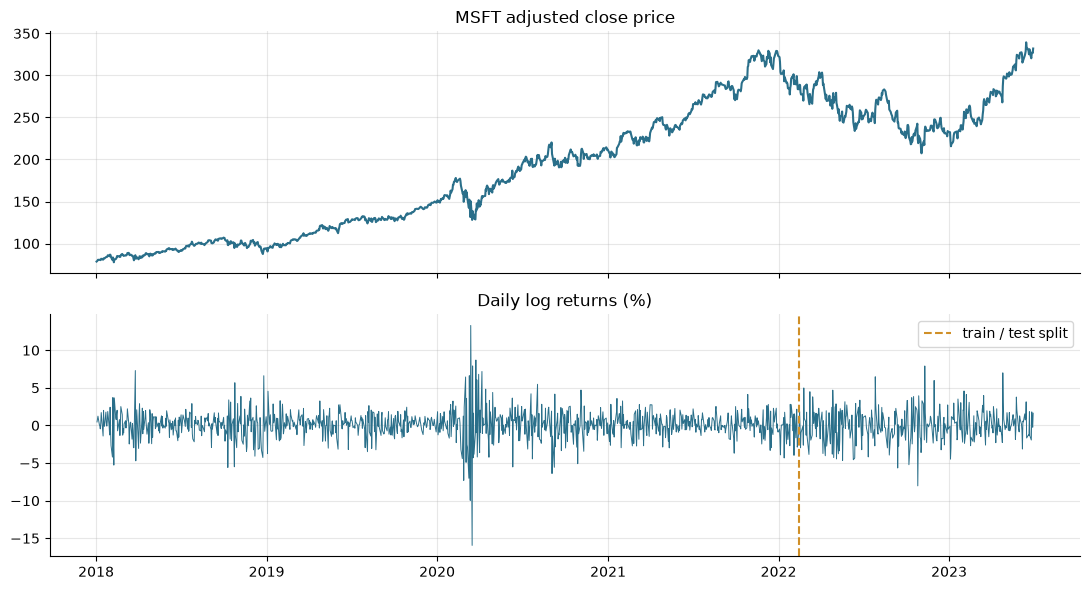

In [15]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(prices, color=TEAL)
ax[0].set_title("MSFT adjusted close price")
ax[1].plot(returns, color=TEAL, lw=0.7)
ax[1].axvline(r_test.index[0], color=GOLD, ls="--", label="train / test split")
ax[1].set_title("Daily log returns (%)")
ax[1].legend()
plt.tight_layout(); save_fig("01_price_returns"); plt.show()

**Interpretation.** Prices trend upward while returns move around zero. The return plot already shows **volatility clustering**:
calm stretches (2019) and turbulent stretches (Q4 2018, March 2020 COVID crash, 2022 rate-hike sell-off). The test period
(Feb 2022 – Jun 2023) is noticeably more volatile than most of the training period, which makes out-of-sample forecasting harder.

In [16]:
def describe_returns(x):
    jb_stat, jb_p = stats.jarque_bera(x)
    return pd.Series({"N": len(x), "Mean": x.mean(), "Std dev": x.std(), "Min": x.min(), "Max": x.max(),
                      "Skewness": stats.skew(x), "Excess kurtosis": stats.kurtosis(x),
                      "Jarque-Bera p-value": jb_p})

pd.DataFrame({"Full": describe_returns(r_all), "Train": describe_returns(r_tr),
              "Test": describe_returns(r_te)}).round(3)

,Full,Train,Test
N,1382.000,1036.000,346.000
Mean,0.104,0.124,0.046
Std dev,1.941,1.886,2.096
Min,-15.945,-15.945,-8.030
Max,13.293,13.293,7.906
Skewness,-0.231,-0.378,0.107
Excess kurtosis,6.757,9.534,1.098
Jarque-Bera p-value,0.000,0.000,0.000


**Interpretation.** The excess kurtosis is far above 0 and the Jarque-Bera test strongly rejects normality: the returns have
**fat tails**. Daily volatility is about 2%, and higher in the test period.

In [17]:
t_stat, p_val = stats.ttest_1samp(r_tr, 0.0)
print(f"Train mean = {r_tr.mean():.3f}%   t = {t_stat:.2f}   p-value = {p_val:.3f}")

Train mean = 0.124%   t = 2.11   p-value = 0.035


**Interpretation.** MSFT rose strongly over 2018–2021, so the training mean (0.12% per day) is statistically
significant at the 5% level (p ≈ 0.035). Economically, however, it is tiny relative to daily volatility (≈1.9%):
$\bar r^2 \approx 0.015$ against $E[r^2] \approx 3.6$, so it accounts for less than 0.5% of the second moment that drives the GARCH variance.
We therefore keep the paper's zero-mean assumption $\mu \equiv 0$ ($r_t = \varepsilon_t$), which keeps our results comparable with its Table II.

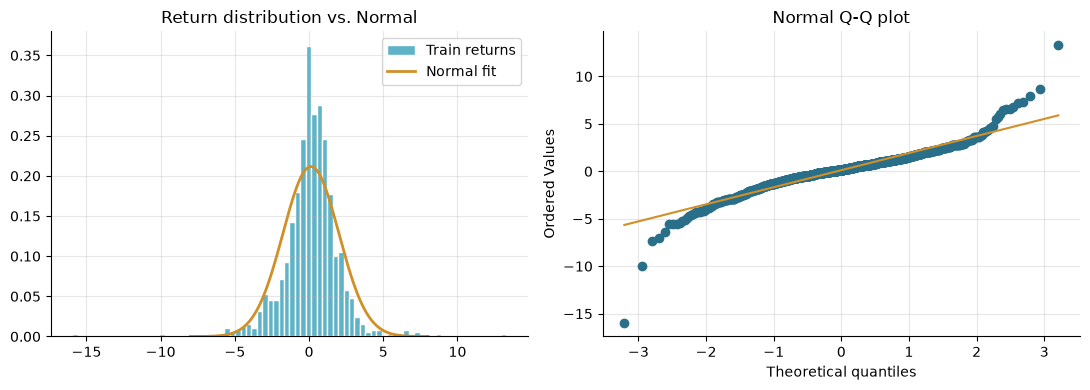

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
grid = np.linspace(-8, 8, 400)
ax[0].hist(r_tr, bins=80, density=True, color=LIGHT, edgecolor="white", label="Train returns")
ax[0].plot(grid, stats.norm.pdf(grid, r_tr.mean(), r_tr.std()), color=GOLD, lw=2, label="Normal fit")
ax[0].set_title("Return distribution vs. Normal"); ax[0].legend()
stats.probplot(r_tr, dist="norm", plot=ax[1])
ax[1].get_lines()[0].set_color(TEAL); ax[1].get_lines()[1].set_color(GOLD)
ax[1].set_title("Normal Q-Q plot")
plt.tight_layout(); save_fig("02_distribution"); plt.show()

**Interpretation.** The histogram is more peaked than the Normal and has heavier tails. In the Q-Q plot the points bend away
from the line at both ends. This motivates the **Student-t extension** in Section 12.

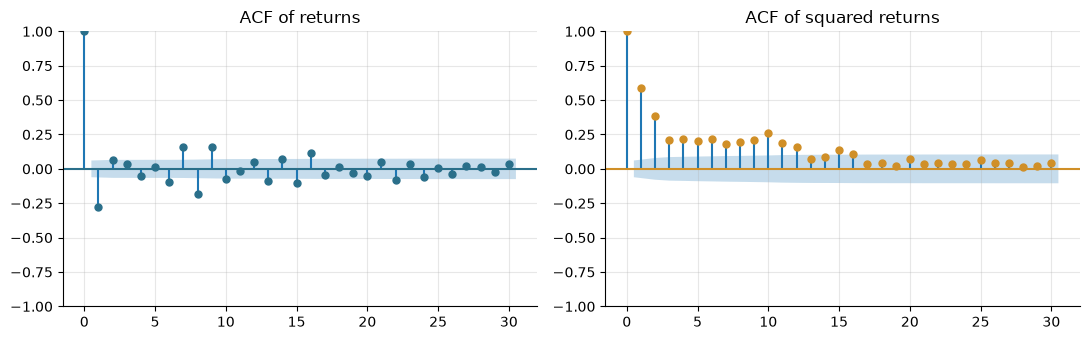

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(r_tr, lags=30, ax=ax[0], color=TEAL, title="ACF of returns")
plot_acf(r_tr**2, lags=30, ax=ax[1], color=GOLD, title="ACF of squared returns")
plt.tight_layout(); save_fig("03_acf"); plt.show()

In [20]:
lb_r  = acorr_ljungbox(r_tr,    lags=[10], return_df=True)
lb_r2 = acorr_ljungbox(r_tr**2, lags=[10], return_df=True)
arch_lm, arch_p, _, _ = het_arch(r_tr, nlags=10)

pd.DataFrame({"Statistic": [lb_r["lb_stat"].iloc[0], lb_r2["lb_stat"].iloc[0], arch_lm],
              "p-value":   [lb_r["lb_pvalue"].iloc[0], lb_r2["lb_pvalue"].iloc[0], arch_p]},
             index=["Ljung-Box(10) on r", "Ljung-Box(10) on r²", "Engle ARCH-LM(10)"]).round(4)

,Statistic,p-value
Ljung-Box(10) on r,191.7889,0.0
Ljung-Box(10) on r²,890.2826,0.0
Engle ARCH-LM(10),392.7603,0.0


**Interpretation.** These are the stylised facts that make GARCH the right tool:
- Squared returns are strongly and persistently autocorrelated (Ljung-Box on $r_t^2$, $p \approx 0$), and Engle's ARCH-LM
  test rejects "no ARCH effects". In other words, **volatility is predictable**.
- Raw returns are also significantly autocorrelated (statistic ≈ 192, against ≈ 890 for squared returns). This comes mostly from the
  whipsaw days of March 2020, when large positive and negative returns alternated. An ARMA mean equation is a possible extension, but
  we keep the paper's zero-mean specification so that the comparison with the paper stays like-for-like.

## 5. The GARCH(1,1) Model and Parameter Transforms

$$ r_t = \varepsilon_t = \sqrt{h_t}\, z_t, \qquad z_t \overset{iid}{\sim} N(0,1), \qquad
   h_t = \omega + \alpha\, \varepsilon_{t-1}^2 + \beta\, h_{t-1} $$

Constraints: $\omega > 0,\ \alpha \ge 0,\ \beta \ge 0$ (positive variance) and $\alpha + \beta < 1$ (covariance stationarity).
Following the paper, the recursion starts from the **back-cast** $h_1 = \frac{1}{T}\sum r_t^2$ of the training data.

### Why transforms?
A Gaussian variational posterior lives on all of $\mathbb{R}^3$, but the GARCH parameters are constrained. The paper
(Proposition 2) maps an unconstrained vector $\theta = (\theta_\omega, \theta_\alpha, \theta_\beta) \in \mathbb{R}^3$ to the valid region:

$$ \omega = e^{\theta_\omega}, \qquad \alpha = f(\theta_\alpha), \qquad \beta = f(\theta_\beta)\,(1-\alpha), \qquad f(x) = \frac{1}{1+e^{-x}} $$

so $\alpha + \beta = \alpha + f(\theta_\beta)(1-\alpha) < 1$ **for every** $\theta$. Stationarity holds by construction, with
no `if` statements and no rescaling. The function is also smooth, so gradients are well defined everywhere.

In [21]:
def to_garch(theta):
    # Map unconstrained theta (..., 3) to GARCH parameters (omega, alpha, beta). Paper, Proposition 2.
    omega = np.exp(theta[..., 0])
    alpha = expit(theta[..., 1])
    beta  = expit(theta[..., 2]) * (1 - alpha)
    return omega, alpha, beta

In [22]:
def from_garch(omega, alpha, beta):
    # Inverse map: GARCH parameters -> unconstrained theta.
    logit = lambda p: np.log(p / (1 - p))
    return np.array([np.log(omega), logit(alpha), logit(beta / (1 - alpha))])

In [23]:
# Check: random theta always gives a valid, stationary GARCH, and the round trip recovers theta
theta_test = rng.normal(0, 3, size=(100_000, 3))
w, a, b = to_garch(theta_test)
print("omega > 0:        ", np.all(w > 0))
print("alpha, beta >= 0: ", np.all(a >= 0) and np.all(b >= 0))
print("alpha + beta < 1: ", np.all(a + b < 1))
print("Round trip OK:    ", np.allclose(from_garch(*to_garch(theta_test[0])), theta_test[0]))

omega > 0:         True
alpha, beta >= 0:  True
alpha + beta < 1:  True
Round trip OK:     True


### Conditional variance filter and log-likelihood

The recursion is a plain loop. `numba` compiles it to machine code, so the samplers below can call it many thousands of times.

In [24]:
@njit
def garch_filter(omega, alpha, beta, r, h0):
    # Conditional variance h_t = omega + alpha * r_{t-1}^2 + beta * h_{t-1}, started at h_1 = h0.
    h = np.empty(len(r))
    h[0] = h0
    for t in range(1, len(r)):
        h[t] = omega + alpha * r[t - 1] ** 2 + beta * h[t - 1]
    return h

In [25]:
H0 = np.mean(r_tr ** 2)   # back-cast from the TRAINING data only

def gaussian_loglik(theta, r, h0=H0):
    # Gaussian GARCH(1,1) log-likelihood log p(y | theta).
    omega, alpha, beta = to_garch(theta)
    h = garch_filter(omega, alpha, beta, r, h0)
    return -0.5 * np.sum(np.log(2 * np.pi * h) + r ** 2 / h)

### Prior and posterior

As in the paper, the prior is a standard normal on the **unconstrained** parameters, $p(\theta) = N(0, I_3)$. Because the prior is
defined directly on $\theta$, the unnormalised log-posterior is simply $\log p(y\mid\theta) + \log p(\theta)$, and no Jacobian is needed.

In [26]:
def log_prior(theta):
    return -0.5 * np.sum(theta ** 2) - 0.5 * len(theta) * np.log(2 * np.pi)

def log_posterior(theta):
    return gaussian_loglik(theta, r_tr) + log_prior(theta)

In [27]:
theta0 = from_garch(0.1, 0.1, 0.8)
print(f"log-likelihood at (0.1, 0.1, 0.8): {gaussian_loglik(theta0, r_tr):.2f}")   # also compiles the numba filter

log-likelihood at (0.1, 0.1, 0.8): -1985.64


### Evaluation metrics (paper, Section III-C)

Squared returns are the proxy for the unobserved variance. Lower is better for all four metrics.

| Metric | Formula |
|---|---|
| NLL | $\tfrac12\sum_t\big[\log(2\pi h_t) + r_t^2/h_t\big]$ |
| RMSE | $\sqrt{\tfrac1T\sum_t (r_t^2 - h_t)^2}$ |
| MAD | $\tfrac1T\sum_t \lvert r_t^2 - h_t\rvert$ |
| QLIK | $\tfrac1T\sum_t \big[\log h_t + r_t^2/h_t\big]$ |

Test-set variances are **one-step-ahead forecasts**: the filter runs through the whole sample with parameters estimated on the training data only.

In [28]:
def variance_path(omega, alpha, beta):
    # One-step-ahead conditional variances over the FULL sample (train + test).
    return garch_filter(omega, alpha, beta, r_all, H0)

def metrics(h, r):
    return {"NLL":  0.5 * np.sum(np.log(2 * np.pi * h) + r ** 2 / h),
            "RMSE": np.sqrt(np.mean((r ** 2 - h) ** 2)),
            "MAD":  np.mean(np.abs(r ** 2 - h)),
            "QLIK": np.mean(np.log(h) + r ** 2 / h)}

In [29]:
def evaluate(omega, alpha, beta):
    # Train and test metrics for one parameter vector.
    h = variance_path(omega, alpha, beta)
    tr = {f"{k} train": v for k, v in metrics(h[:n_train], r_tr).items()}
    te = {f"{k} test": v  for k, v in metrics(h[n_train:], r_te).items()}
    return {**tr, **te}

## 6. Benchmark 1: Quasi-Maximum Likelihood (QML)

We maximise the log-likelihood over $\theta$. Because of the transforms, this is an **unconstrained** optimisation.
We then cross-check the estimates against the `arch` package, which is the industry-standard constrained optimiser.

In [30]:
t0 = time.perf_counter()
qml = minimize(lambda th: -gaussian_loglik(th, r_tr), x0=np.zeros(3), method="Nelder-Mead",
               options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 5000})
time_qml = time.perf_counter() - t0

theta_qml = qml.x
omega_qml, alpha_qml, beta_qml = to_garch(theta_qml)
print(f"Converged: {qml.success}   ({qml.nfev} likelihood evaluations, {time_qml:.3f}s)")
print(f"QML:  omega = {omega_qml:.3f}   alpha = {alpha_qml:.3f}   beta = {beta_qml:.3f}   "
      f"alpha+beta = {alpha_qml + beta_qml:.3f}")

Converged: True   (380 likelihood evaluations, 0.005s)
QML:  omega = 0.160   alpha = 0.186   beta = 0.769   alpha+beta = 0.955


In [31]:
arch_fit = arch_model(r_tr, mean="Zero", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")
print(arch_fit.params.round(3).to_string())

omega       0.159
alpha[1]    0.185
beta[1]     0.770


**Interpretation.** Our QML estimates ($\omega \approx 0.16,\ \alpha \approx 0.19,\ \beta \approx 0.77$) match `arch`
(small differences come from `arch`'s different back-cast) and match the **paper's Table II** for MSFT ($0.15, 0.19, 0.77$).
This confirms that the data and likelihood are implemented correctly.

Persistence $\alpha+\beta \approx 0.955$ means volatility shocks decay slowly, with a half-life of $\ln 0.5/\ln 0.955 \approx 15$ trading days.

## 7. Benchmark 2: MCMC (Random-Walk Metropolis)

MCMC is the standard Bayesian approach and the **reference** against which the paper judges VI. We sample $\theta$ from the exact posterior
with a Random-Walk Metropolis sampler:
- Proposal: $\theta' = \theta + \epsilon$, $\epsilon \sim N\big(0, \tfrac{2.38^2}{d}\,\hat\Sigma\big)$, where $\hat\Sigma$ is the inverse Hessian at the posterior mode
  (the classic optimal-scaling rule, which targets roughly 25–35% acceptance).
- 30,000 iterations, the first 10,000 discarded as burn-in.

In [32]:
mode = minimize(lambda th: -log_posterior(th), theta_qml, method="Nelder-Mead").x
Sigma_hat = np.linalg.inv(-approx_hess(mode, log_posterior))
print("Posterior mode (omega, alpha, beta):", np.round(to_garch(mode), 3))

Posterior mode (omega, alpha, beta): [0.22  0.199 0.731]


In [33]:
def random_walk_metropolis(log_target, start, cov, n_iter, seed=SEED):
    rng = np.random.default_rng(seed)
    chol = np.linalg.cholesky(2.38 ** 2 / len(start) * cov)
    chain = np.empty((n_iter, len(start)))
    current, lp_current, accepted = start.copy(), log_target(start), 0
    for i in range(n_iter):
        proposal = current + chol @ rng.standard_normal(len(start))
        lp_prop = log_target(proposal)
        if np.log(rng.uniform()) < lp_prop - lp_current:      # Metropolis acceptance rule
            current, lp_current = proposal, lp_prop
            accepted += 1
        chain[i] = current
    return chain, accepted / n_iter

In [34]:
N_MCMC, BURN = 30_000, 10_000
t0 = time.perf_counter()
chain, acc_rate = random_walk_metropolis(log_posterior, mode, Sigma_hat, N_MCMC)
time_mcmc = time.perf_counter() - t0

theta_mcmc = chain[BURN:]
print(f"Acceptance rate: {acc_rate:.1%}   Run time: {time_mcmc:.2f}s   Kept draws: {len(theta_mcmc)}")

Acceptance rate: 32.8%   Run time: 0.31s   Kept draws: 20000


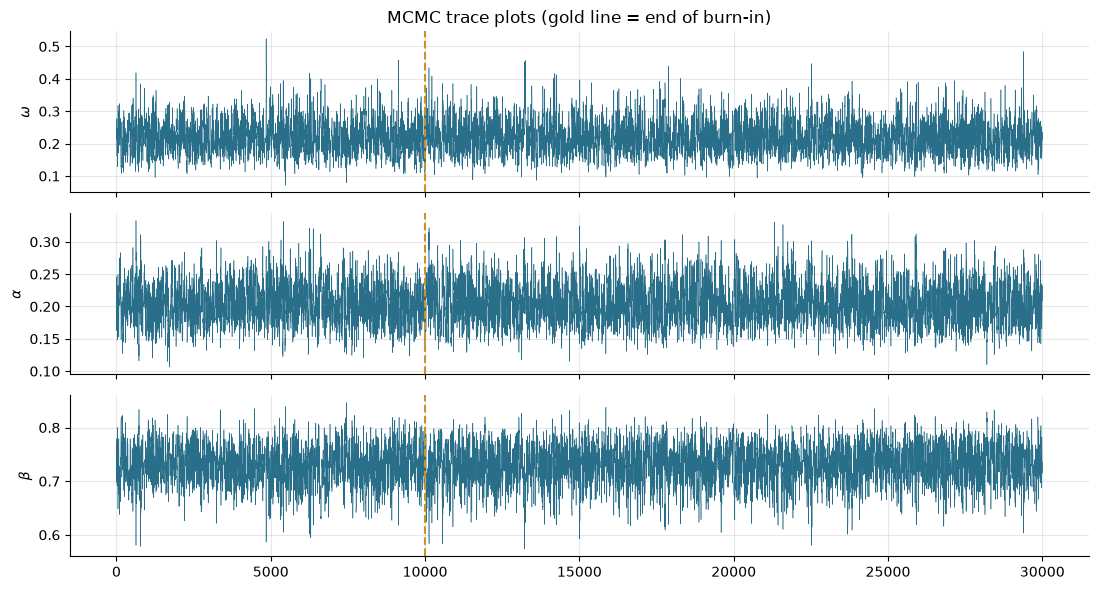

In [35]:
names = ["$\\omega$", "$\\alpha$", "$\\beta$"]
draws_mcmc = np.column_stack(to_garch(chain))
fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for j in range(3):
    ax[j].plot(draws_mcmc[:, j], color=TEAL, lw=0.4)
    ax[j].axvline(BURN, color=GOLD, ls="--")
    ax[j].set_ylabel(names[j])
ax[0].set_title("MCMC trace plots (gold line = end of burn-in)")
plt.tight_layout(); save_fig("04_mcmc_trace"); plt.show()

**Interpretation.** The chains mix well: there are no trends or long flat stretches after burn-in, and the acceptance rate is
inside the 25–35% target band. We treat these draws as the "true" posterior below.

## 8. Variational Inference 1: Black-Box VI (the paper's Algorithm 1)

VI replaces sampling with **optimisation**. We choose a Gaussian $q_\zeta(\theta) = N(\mu, \text{diag}(\sigma^2))$ and maximise the
**lower bound** (ELBO):

$$ \mathcal{L}(\zeta) = \mathbb{E}_{q_\zeta}\big[\,h_\zeta(\theta)\,\big], \qquad h_\zeta(\theta) = \log p(y\mid\theta) + \log p(\theta) - \log q_\zeta(\theta) $$

Maximising $\mathcal{L}$ is equivalent to minimising $\text{KL}\big(q_\zeta \,\|\, p(\theta\mid y)\big)$.

**Black-box gradient (log-derivative trick, paper eq. 5).** No derivatives of the GARCH likelihood are needed, only likelihood evaluations:

$$ \nabla_\zeta \mathcal{L} \approx \frac{1}{S}\sum_{s=1}^{S} \nabla_\zeta \log q_\zeta(\theta_s)\,\big(h_\zeta(\theta_s) - c\big), \qquad \theta_s \sim q_\zeta $$

where $c$ is the sample mean of $h$, a standard control variate that reduces gradient noise without introducing bias.
We parameterise the standard deviations on the log scale so they stay positive.

**Hyperparameters taken from the paper:** learning rate 0.005, $S = 50$ draws, momentum 0.4, 2,500 iterations,
$\mu_0 = 0$, $\Sigma_0 = 0.1 I$, prior $N(0, I)$.

In [36]:
def log_q_diag(theta, mu, log_sig):
    # log density of the diagonal Gaussian q, for each row of theta.
    z = (theta - mu) / np.exp(log_sig)
    return np.sum(-0.5 * z ** 2 - log_sig - 0.5 * np.log(2 * np.pi), axis=1)

In [37]:
def bbvi(log_target, dim=3, n_iter=2500, S=50, lr=0.005, momentum=0.4, seed=SEED):
    rng = np.random.default_rng(seed)
    mu, log_sig = np.zeros(dim), np.full(dim, 0.5 * np.log(0.1))     # mu_0 = 0, Sigma_0 = 0.1 I
    velocity, lb_history = np.zeros(2 * dim), []
    for _ in range(n_iter):
        eps = rng.standard_normal((S, dim))
        theta = mu + np.exp(log_sig) * eps                            # 1. sample from q
        h = np.array([log_target(t) for t in theta]) - log_q_diag(theta, mu, log_sig)   # 2. h-function
        score = np.hstack([eps / np.exp(log_sig), eps ** 2 - 1])      # 3. grad of log q wrt (mu, log_sig)
        grad = np.mean(score * (h - h.mean())[:, None], axis=0)       # 4. black-box gradient with control variate
        velocity = momentum * velocity + (1 - momentum) * grad        # 5. momentum update
        mu, log_sig = mu + lr * velocity[:dim], log_sig + lr * velocity[dim:]
        lb_history.append(h.mean())
    return mu, np.exp(log_sig), np.array(lb_history)

In [38]:
t0 = time.perf_counter()
mu_bbvi, sig_bbvi, lb_bbvi = bbvi(log_posterior)
time_bbvi = time.perf_counter() - t0
print(f"Run time: {time_bbvi:.2f}s   Final lower bound (mean of last 100 iters): {lb_bbvi[-100:].mean():.2f}")

Run time: 1.08s   Final lower bound (mean of last 100 iters): -1946.22


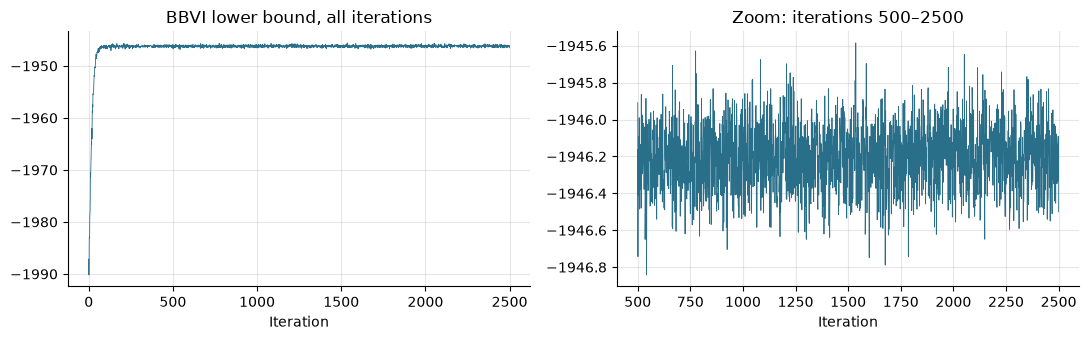

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(lb_bbvi, color=TEAL, lw=0.6)
ax[0].set_title("BBVI lower bound, all iterations"); ax[0].set_xlabel("Iteration")
ax[1].plot(np.arange(500, 2500), lb_bbvi[500:], color=TEAL, lw=0.6)
ax[1].set_title("Zoom: iterations 500–2500"); ax[1].set_xlabel("Iteration")
plt.tight_layout(); plt.show()

**Interpretation.** The lower bound rises quickly and reaches a plateau after roughly 1,000–1,500 iterations, which matches the paper's
observation that "typically 1500 iterations are sufficient" (Fig. 1). The remaining wiggle is Monte Carlo noise from using $S = 50$ draws per step.

In [40]:
N_DRAWS = 20_000
theta_bbvi = mu_bbvi + sig_bbvi * rng.standard_normal((N_DRAWS, 3))   # draws from q, then transform (paper eq. 6)

## 9. Variational Inference 2: Full-Covariance Gaussian VI in PyTorch

The paper stresses that a **full covariance matrix** (its MGVB/EMGVB optimisers) captures the strong posterior correlation between
GARCH parameters, which a diagonal $q$ cannot. We implement full-covariance Gaussian VI with the **reparameterisation trick**:

$$ \theta = \mu + L\,\epsilon, \qquad \epsilon \sim N(0, I), \qquad \Sigma = LL^\top \;(L \text{ lower-triangular, positive diagonal}) $$

so the ELBO is a differentiable function of $(\mu, L)$ and PyTorch's automatic differentiation provides the gradients:

$$ \text{ELBO} = \underbrace{\mathbb{E}_q\big[\log p(y\mid\theta) + \log p(\theta)\big]}_{\text{Monte Carlo, } S=10} + \underbrace{\textstyle\sum_i \log L_{ii} + \tfrac{d}{2}\log(2\pi e)}_{\text{entropy of } q,\ \text{exact}} $$

The GARCH recursion runs on all $S$ samples at once (vectorised), and the parameters are updated with Adam.

In [41]:
r_tr_t = torch.tensor(r_tr)

def to_garch_torch(theta):
    # Same transform as to_garch, written in PyTorch so gradients can flow through it.
    omega = torch.exp(theta[:, 0])
    alpha = torch.sigmoid(theta[:, 1])
    beta  = torch.sigmoid(theta[:, 2]) * (1 - alpha)
    return omega, alpha, beta

In [42]:
def garch_variance_torch(omega, alpha, beta, r, h0=H0):
    # Vectorised over S parameter draws: returns an (S, T) tensor of conditional variances.
    h = [torch.full_like(omega, h0)]
    for t in range(1, len(r)):
        h.append(omega + alpha * r[t - 1] ** 2 + beta * h[-1])
    return torch.stack(h, dim=1)

In [43]:
def gaussian_loglik_torch(theta, r=r_tr_t):
    h = garch_variance_torch(*to_garch_torch(theta), r)
    return -0.5 * torch.sum(torch.log(2 * np.pi * h) + r ** 2 / h, dim=1)

def log_prior_torch(theta):
    return -0.5 * torch.sum(theta ** 2, dim=1) - 0.5 * theta.shape[1] * np.log(2 * np.pi)

In [44]:
def cholesky_factor(L_raw):
    # Lower-triangular L with a positive diagonal (exp of the raw diagonal).
    return torch.tril(L_raw, -1) + torch.diag(torch.exp(torch.diagonal(L_raw)))

def elbo(mu, L_raw, loglik_fn, S):
    L = cholesky_factor(L_raw)
    theta = mu + torch.randn(S, len(mu)) @ L.T                     # reparameterisation trick
    entropy = torch.sum(torch.log(torch.diagonal(L))) + 0.5 * len(mu) * np.log(2 * np.pi * np.e)
    return torch.mean(loglik_fn(theta) + log_prior_torch(theta)) + entropy

In [45]:
def fit_full_vi(loglik_fn, dim, n_iter=1500, S=10, lr=0.01):
    mu = torch.zeros(dim, requires_grad=True)
    L_raw = torch.diag(torch.full((dim,), 0.5 * np.log(0.1))).requires_grad_(True)   # Sigma_0 = 0.1 I
    optimizer = torch.optim.Adam([mu, L_raw], lr=lr)
    history = []
    for _ in range(n_iter):
        optimizer.zero_grad()
        loss = -elbo(mu, L_raw, loglik_fn, S)       # minimise the negative ELBO
        loss.backward()
        optimizer.step()
        history.append(-loss.item())
    return mu.detach(), cholesky_factor(L_raw).detach(), np.array(history)

In [46]:
t0 = time.perf_counter()
mu_fvi, L_fvi, elbo_fvi = fit_full_vi(gaussian_loglik_torch, dim=3)
time_fvi = time.perf_counter() - t0
print(f"Run time: {time_fvi:.1f}s")

Run time: 15.9s


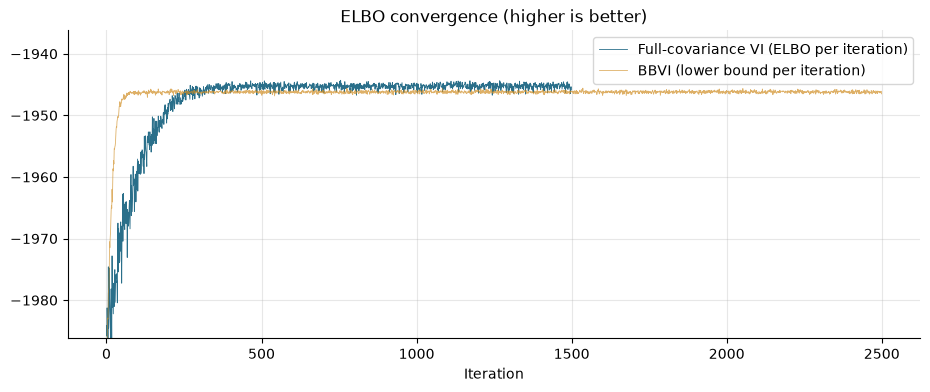

In [47]:
plt.plot(elbo_fvi, color=TEAL, lw=0.6, label="Full-covariance VI (ELBO per iteration)")
plt.plot(lb_bbvi, color=GOLD, lw=0.6, alpha=0.7, label="BBVI (lower bound per iteration)")
plt.ylim(lb_bbvi[-100:].mean() - 40, lb_bbvi[-100:].mean() + 10)
plt.title("ELBO convergence (higher is better)"); plt.xlabel("Iteration"); plt.legend(); save_fig("05_elbo"); plt.show()

In [48]:
def final_elbo(mu, L, loglik_fn, n=4000):
    # Precise ELBO estimate at the optimum, using many draws.
    with torch.no_grad():
        return elbo(mu, torch.tril(L, -1) + torch.diag(torch.log(torch.diagonal(L))), loglik_fn, n).item()

elbo_gauss = final_elbo(mu_fvi, L_fvi, gaussian_loglik_torch)
print(f"Full-covariance VI final ELBO: {elbo_gauss:.2f}")
print(f"BBVI final lower bound:       {lb_bbvi[-200:].mean():.2f}")

Full-covariance VI final ELBO: -1945.27
BBVI final lower bound:       -1946.21


**Interpretation.** Both VI methods converge. The full-covariance ELBO ends **above** the diagonal BBVI bound. Because a higher ELBO
means a smaller KL divergence to the true posterior, the full-covariance $q$ is a better approximation. The paper finds the same ordering
(MGVB/EMGVB above BBVI/QBVI in Table II).

In [49]:
theta_fvi = (mu_fvi + torch.randn(N_DRAWS, 3) @ L_fvi.T).numpy()

## 10. Results: Comparing QML, MCMC and VI

### 10.1 Parameter estimates (compare with the paper's Table II, GARCH(1,1), MSFT)
For the Bayesian methods we report the mean and standard deviation of the **transformed** posterior draws (paper eq. 6).

In [50]:
posterior_draws = {"MCMC": theta_mcmc, "BBVI (diagonal)": theta_bbvi, "Full-cov VI": theta_fvi}

def summarise(theta):
    w, a, b = to_garch(theta)
    return {p: f"{x.mean():.3f} ± {x.std():.3f}" for p, x in zip(["omega", "alpha", "beta"], [w, a, b])}

param_table = pd.DataFrame({"QML": {"omega": f"{omega_qml:.3f}", "alpha": f"{alpha_qml:.3f}", "beta": f"{beta_qml:.3f}"},
                            **{k: summarise(v) for k, v in posterior_draws.items()}}).T
param_table

,omega,alpha,beta
QML,0.160,0.186,0.769
MCMC,0.217 ± 0.049,0.203 ± 0.031,0.731 ± 0.036
BBVI (diagonal),0.214 ± 0.022,0.201 ± 0.023,0.732 ± 0.023
Full-cov VI,0.220 ± 0.050,0.200 ± 0.029,0.732 ± 0.035


In [51]:
paper_table = pd.DataFrame({"omega": ["0.15", "0.200 ± 0.046", "0.196 ± 0.021", "0.205 ± 0.047"],
                            "alpha": ["0.19", "0.203 ± 0.031", "0.199 ± 0.023", "0.201 ± 0.030"],
                            "beta":  ["0.77", "0.737 ± 0.036", "0.740 ± 0.023", "0.736 ± 0.035"]},
                           index=["QML (ML)", "MCMC", "BBVI", "MGVB (full cov.)"])
print("Paper, Table II (MSFT, GARCH(1,1)):")
paper_table

Paper, Table II (MSFT, GARCH(1,1)):


,omega,alpha,beta
QML (ML),0.15,0.19,0.77
MCMC,0.200 ± 0.046,0.203 ± 0.031,0.737 ± 0.036
BBVI,0.196 ± 0.021,0.199 ± 0.023,0.740 ± 0.023
MGVB (full cov.),0.205 ± 0.047,0.201 ± 0.030,0.736 ± 0.035


**Interpretation.**
- **Replication:** all of our estimates are within about 0.02 of the paper's corresponding values. The remaining gap comes from Yahoo's
  current dividend adjustment and small implementation differences.
- **Posterior means:** MCMC, BBVI and full-covariance VI all agree closely. Bayesian means sit slightly above QML for $\omega$ and below for $\beta$ because the
  posterior is skewed: there is more room for $\beta$ to fall than to rise towards the stationarity bound.
- **Posterior uncertainty:** the full-covariance VI standard deviations match MCMC. The **diagonal BBVI understates the uncertainty**
  (posterior SD of $\omega$ about 55% smaller, $\beta$ about 35% smaller). This is the well-known effect of ignoring posterior correlation,
  and the paper reports it too (BBVI 0.021 vs MCMC 0.046 for $\omega$).

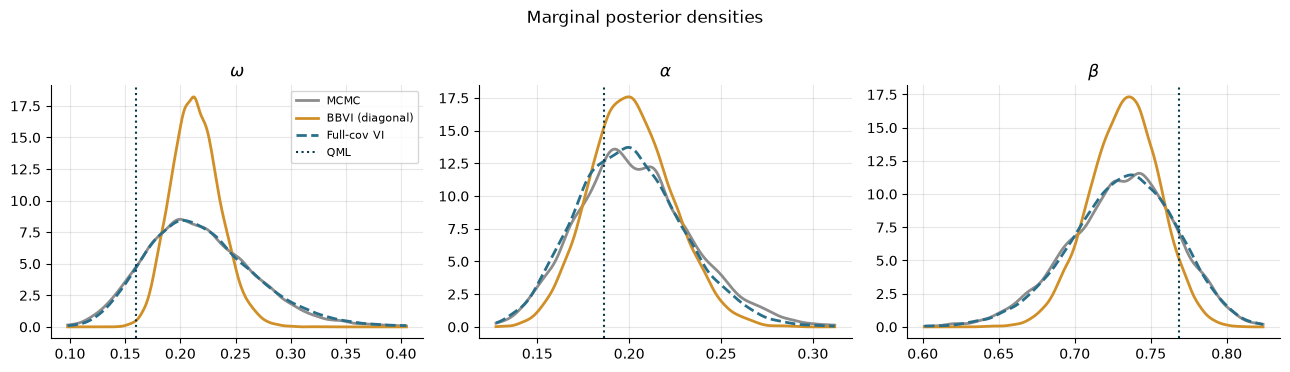

In [52]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
qml_vals = [omega_qml, alpha_qml, beta_qml]
styles = {"MCMC": (GREY, "-"), "BBVI (diagonal)": (GOLD, "-"), "Full-cov VI": (TEAL, "--")}
for name, th in posterior_draws.items():
    draws = to_garch(th)
    for j in range(3):
        kde = stats.gaussian_kde(draws[j])
        grid = np.linspace(*np.percentile(draws_mcmc[BURN:, j], [0.1, 99.9]), 300)
        ax[j].plot(grid, kde(grid), color=styles[name][0], ls=styles[name][1], lw=2, label=name)
for j in range(3):
    ax[j].axvline(qml_vals[j], color=DARK, ls=":", label="QML"); ax[j].set_title(names[j])
ax[0].legend(fontsize=8); plt.suptitle("Marginal posterior densities", y=1.02); plt.tight_layout(); save_fig("06_posteriors"); plt.show()

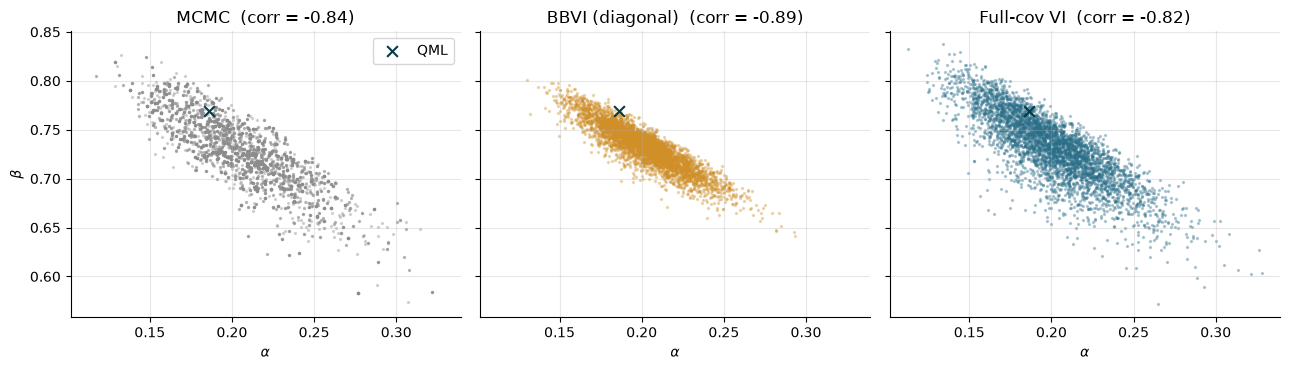

In [53]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for k, (name, th) in enumerate(posterior_draws.items()):
    w, a, b = to_garch(th[:4000])
    ax[k].scatter(a, b, s=2, alpha=0.3, color=[GREY, GOLD, TEAL][k])
    ax[k].scatter(alpha_qml, beta_qml, color=DARK, marker="x", s=60, label="QML")
    ax[k].set_title(f"{name}  (corr = {np.corrcoef(a, b)[0, 1]:.2f})"); ax[k].set_xlabel(names[1])
ax[0].set_ylabel(names[2]); ax[0].legend(); plt.tight_layout(); save_fig("07_alpha_beta"); plt.show()

**Interpretation.** In the MCMC posterior, $\alpha$ and $\beta$ are strongly **negatively correlated**: more reaction to shocks requires
less persistence to fit the same data. Full-covariance VI reproduces both the shape and the spread of this cloud.
Diagonal BBVI also shows a negative correlation, but only because the transform $\beta = f(\theta_\beta)(1-\alpha)$ links the two
parameters mechanically. In $\theta$-space, a diagonal $q$ cannot represent the correlation between $\theta_\omega$ and $\theta_\beta$,
so its cloud is **too compact** and misses the high-$\alpha$/low-$\beta$ tail. This is the paper's Fig. 1 point about "the importance of
allowing for a full-covariance specification".

### 10.2 In-sample and out-of-sample performance

In [54]:
point_estimates = {"QML": (omega_qml, alpha_qml, beta_qml)}
for name, th in posterior_draws.items():
    point_estimates[name] = tuple(x.mean() for x in to_garch(th))     # transformed posterior mean (paper eq. 6)

perf = pd.DataFrame({k: evaluate(*v) for k, v in point_estimates.items()}).T
perf.round(3)

,NLL train,RMSE train,MAD train,QLIK train,NLL test,RMSE test,MAD test,QLIK test
QML,1934.443,10.413,3.734,1.897,764.648,8.014,4.601,2.582
MCMC,1935.156,10.334,3.711,1.898,765.825,8.032,4.574,2.589
BBVI (diagonal),1935.113,10.337,3.703,1.898,766.080,8.029,4.564,2.590
Full-cov VI,1935.208,10.337,3.703,1.898,765.849,8.025,4.558,2.589


In [55]:
pct_vs_qml = 100 * (perf / perf.loc["QML"] - 1)
print("Percentage difference relative to QML (paper's Table I convention):")
pct_vs_qml.drop("QML").round(2)

Percentage difference relative to QML (paper's Table I convention):


,NLL train,RMSE train,MAD train,QLIK train,NLL test,RMSE test,MAD test,QLIK test
MCMC,0.04,-0.75,-0.60,0.07,0.15,0.23,-0.60,0.26
BBVI (diagonal),0.03,-0.72,-0.81,0.07,0.19,0.18,-0.82,0.32
Full-cov VI,0.04,-0.73,-0.84,0.08,0.16,0.13,-0.94,0.27


**Interpretation.**
- In-sample (train NLL), QML is best by construction, since it *maximises* the training likelihood. The Bayesian methods are within about 0.1%.
- Out of sample, all methods are within roughly 1% of QML on every metric. This is the paper's main result: **VI loses essentially nothing in forecasting
  accuracy relative to QML and MCMC**.
- The test NLL is higher per day than the train NLL because the test period (2022–23) was more volatile.
- **Check against the paper:** its Table II reports a test NLL of 761.4 (QML) and 762.9 (MCMC) for MSFT. We get 764.6 and 765.8,
  which is very close.

### 10.3 Computational cost

In [56]:
cost = pd.DataFrame({
    "Run time (s)": [time_qml, time_mcmc, time_bbvi, time_fvi],
    "Likelihood evaluations": [qml.nfev, N_MCMC, 2500 * 50, 1500 * 10],
    "Gradients of likelihood needed?": ["No", "No", "No", "Yes (autodiff)"],
    "Output": ["Point estimate", "Posterior draws", "Gaussian posterior", "Gaussian posterior"]},
    index=["QML", "MCMC", "BBVI (diagonal)", "Full-cov VI"])
cost.round(2)

,Run time (s),Likelihood evaluations,Gradients of likelihood needed?,Output
QML,0.01,380,No,Point estimate
MCMC,0.31,30000,No,Posterior draws
BBVI (diagonal),1.08,125000,No,Gaussian posterior
Full-cov VI,15.87,15000,Yes (autodiff),Gaussian posterior


**Interpretation (honest assessment).** For a **3-parameter** GARCH model, a well-tuned Random-Walk Metropolis sampler is *not* a bottleneck:
it needs fewer likelihood evaluations than BBVI (30,000 vs 125,000) and finishes faster. The PyTorch run time is dominated by Python
overhead in the recursion loop rather than by the algorithm itself. So this experiment does **not** show that VI is faster than MCMC for small
GARCH models, and the paper does not claim this either.

VI's practical advantages here are different:
1. **Convergence is easy to monitor**: one scalar ELBO curve instead of chain diagnostics.
2. **The tuning is generic**: the same hyperparameters work for every stock and model (the paper's argument for large-scale use, see Section 13),
   whereas our MCMC needed a mode search and a Hessian to tune its proposal.
3. **The result is an analytical distribution** that can be sampled instantly and reused, for example for forecast bands.
4. **It scales to high dimensions**, where random-walk MCMC mixes very slowly (e.g. multivariate GARCH or Bayesian neural networks). That is
   where the computational gains in the VI literature come from.

## 11. Volatility Forecasts with Posterior Uncertainty

A Bayesian estimate gives a whole distribution of volatility paths, not just one. For each posterior draw we filter the series
and report the 5%–95% band of **annualised** conditional volatility $\sqrt{252\,h_t}$ (compare the paper's Fig. 2, bottom).

In [57]:
def volatility_band(theta, n=2000, q=(5, 50, 95)):
    # Percentiles of annualised volatility across n posterior draws.
    paths = np.array([variance_path(*to_garch(t)) for t in theta[:n]])
    return np.percentile(np.sqrt(252 * paths), q, axis=0)

band_mcmc = volatility_band(theta_mcmc[::10])
band_fvi  = volatility_band(theta_fvi)
band_bbvi = volatility_band(theta_bbvi)
vol_qml   = np.sqrt(252 * variance_path(omega_qml, alpha_qml, beta_qml))

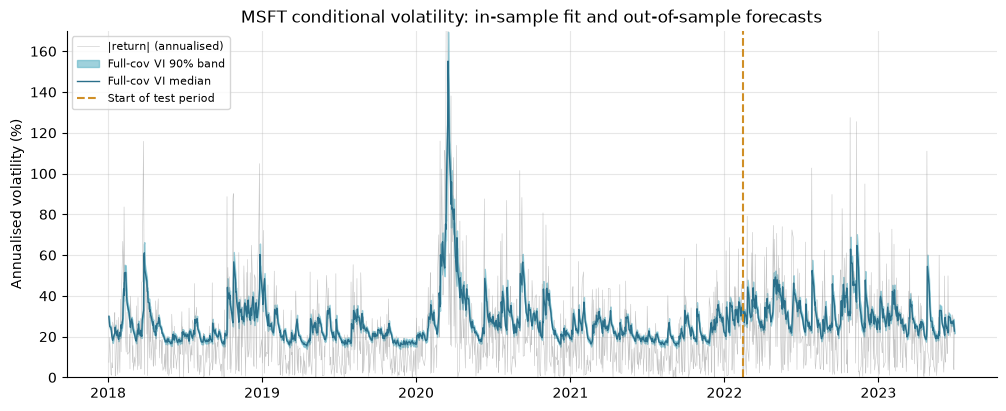

In [58]:
dates = returns.index
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(dates, np.sqrt(252) * np.abs(r_all), color=GREY, lw=0.4, alpha=0.5, label="|return| (annualised)")
ax.fill_between(dates, band_fvi[0], band_fvi[2], color=LIGHT, alpha=0.6, label="Full-cov VI 90% band")
ax.plot(dates, band_fvi[1], color=TEAL, lw=1, label="Full-cov VI median")
ax.axvline(r_test.index[0], color=GOLD, ls="--", label="Start of test period")
ax.set_ylim(0, 170); ax.set_ylabel("Annualised volatility (%)")
ax.set_title("MSFT conditional volatility: in-sample fit and out-of-sample forecasts"); ax.legend(loc="upper left", fontsize=8)
save_fig("08_volatility_band"); plt.show()

**Interpretation.** The model tracks the main volatility regimes: the late-2018 sell-off, the **March 2020 COVID spike** (annualised
volatility peaks above 150%), and the 2022 rate-hike period in the test set. Volatility rises right after large absolute returns and then decays
slowly, which is the clustering pattern implied by $\alpha + \beta \approx 0.95$.

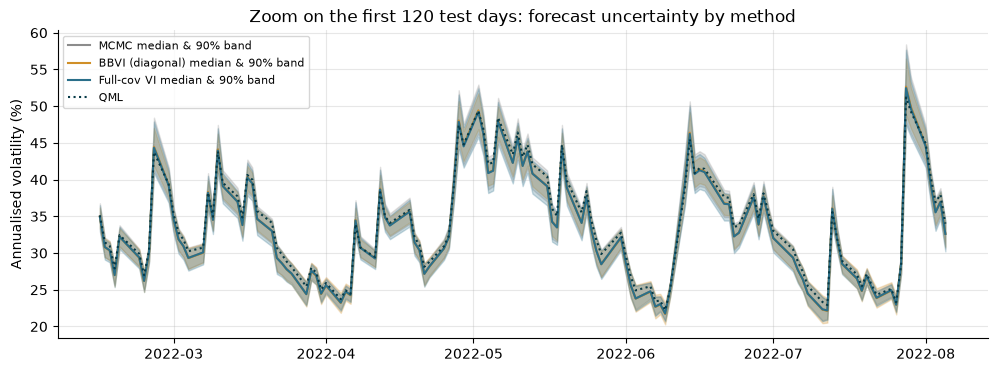

In [59]:
test_window = slice(n_train, n_train + 120)
fig, ax = plt.subplots(figsize=(12, 4))
for band, col, lab in [(band_mcmc, GREY, "MCMC"), (band_bbvi, GOLD, "BBVI (diagonal)"), (band_fvi, TEAL, "Full-cov VI")]:
    ax.fill_between(dates[test_window], band[0][test_window], band[2][test_window], color=col, alpha=0.25)
    ax.plot(dates[test_window], band[1][test_window], color=col, lw=1.5, label=f"{lab} median & 90% band")
ax.plot(dates[test_window], vol_qml[test_window], color=DARK, ls=":", label="QML")
ax.set_ylabel("Annualised volatility (%)"); ax.set_title("Zoom on the first 120 test days: forecast uncertainty by method")
ax.legend(fontsize=8); save_fig("09_forecast_bands"); plt.show()

In [60]:
width = lambda band: np.mean(band[2][n_train:] - band[0][n_train:])
print(f"Average width of the 90% volatility band in the test set (annualised %-points):")
print(f"  MCMC: {width(band_mcmc):.2f}   Full-cov VI: {width(band_fvi):.2f}   BBVI (diagonal): {width(band_bbvi):.2f}")

Average width of the 90% volatility band in the test set (annualised %-points):
  MCMC: 3.47   Full-cov VI: 3.53   BBVI (diagonal): 3.14


**Interpretation.** The full-covariance VI band almost coincides with the MCMC band, so its **uncertainty quantification is reliable**.
The diagonal BBVI band is about 10% narrower, which means it is **over-confident**. The bands are narrow overall (about ±1.7 vol points):
with 1,036 training days, parameter uncertainty is small compared with the volatility level itself. QML gives no band at all. These bands are useful in practice, for example to test whether
tomorrow's volatility is significantly higher than today's, or to report a distribution of Value-at-Risk instead of a single number.

## 12. Extension: Student-t Innovations

The EDA showed fat tails. We replace $z_t \sim N(0,1)$ with a **standardised Student-t** with $\nu > 2$ degrees of freedom (unit variance):

$$ \log p(r_t \mid h_t, \nu) = \log\Gamma\!\left(\tfrac{\nu+1}{2}\right) - \log\Gamma\!\left(\tfrac{\nu}{2}\right) - \tfrac12\log\big(\pi(\nu-2)h_t\big)
   - \tfrac{\nu+1}{2}\log\!\left(1 + \frac{r_t^2}{(\nu-2)h_t}\right) $$

$\nu$ gets its own unconstrained parameter, $\nu = 2 + e^{\theta_\nu}$ (the same idea as the paper's GED transform), with an $N(0,1)$ prior on $\theta_\nu$.
We estimate it with the same full-covariance VI code, now in 4 dimensions.

*Note on the original notebook:* an earlier version added a "MAP penalty" $0.1\sum\mu^2$ on top of the KL term. That counts the prior
twice and changes the objective, so its loss was not an ELBO and could not be compared with the Gaussian model. It has been removed.
The KL/prior term in the ELBO **already** provides the regularisation.

In [61]:
def student_t_loglik_torch(theta, r=r_tr_t):
    h = garch_variance_torch(*to_garch_torch(theta[:, :3]), r)
    nu = (2 + torch.exp(theta[:, 3]))[:, None]
    ll = (torch.lgamma((nu + 1) / 2) - torch.lgamma(nu / 2) - 0.5 * torch.log(np.pi * (nu - 2) * h)
          - (nu + 1) / 2 * torch.log(1 + r ** 2 / ((nu - 2) * h)))
    return ll.sum(dim=1)

In [62]:
t0 = time.perf_counter()
mu_t, L_t, elbo_t_hist = fit_full_vi(student_t_loglik_torch, dim=4)
time_t = time.perf_counter() - t0
theta_t = (mu_t + torch.randn(N_DRAWS, 4) @ L_t.T).numpy()
print(f"Run time: {time_t:.1f}s")

Run time: 15.9s


In [63]:
w_t, a_t, b_t = to_garch(theta_t[:, :3])
nu_t = 2 + np.exp(theta_t[:, 3])
pd.DataFrame({"mean": [w_t.mean(), a_t.mean(), b_t.mean(), nu_t.mean()],
              "sd":   [w_t.std(),  a_t.std(),  b_t.std(),  nu_t.std()],
              "5%":   np.percentile([w_t, a_t, b_t, nu_t], 5, axis=1),
              "95%":  np.percentile([w_t, a_t, b_t, nu_t], 95, axis=1)},
             index=["omega", "alpha", "beta", "nu"]).round(3)

,mean,sd,5%,95%
omega,0.232,0.063,0.145,0.348
alpha,0.208,0.034,0.156,0.267
beta,0.727,0.041,0.657,0.790
nu,7.356,1.596,5.192,10.246


**Interpretation.** The posterior mean of $\nu$ is about 7, with a 90% interval of roughly 5–10. That is far from the Normal limit
($\nu \to \infty$), so the data favour **fat-tailed innovations** even after allowing for time-varying volatility. The GARCH parameters
barely change and persistence $\alpha + \beta$ stays around 0.93–0.94.

### Gaussian vs Student-t: which model is better?

We use three criteria that are valid for comparing two different likelihoods:
1. **ELBO**, a lower bound on the log marginal likelihood $\log p(y)$. A higher value means more evidence for the model.
2. **Out-of-sample predictive log-likelihood** on the test set. This is the most direct forecasting test.
3. **Q-Q plots of standardised residuals** $z_t = r_t/\sqrt{h_t}$ against each model's assumed distribution.

In [64]:
elbo_student = final_elbo(mu_t, L_t, student_t_loglik_torch)
print(f"ELBO Gaussian:  {elbo_gauss:.2f}")
print(f"ELBO Student-t: {elbo_student:.2f}")
print(f"Difference:     {elbo_student - elbo_gauss:.2f}  (log-evidence units, Student-t minus Gaussian)")

ELBO Gaussian:  -1945.27
ELBO Student-t: -1934.57
Difference:     10.70  (log-evidence units, Student-t minus Gaussian)


In [65]:
r_all_t = torch.tensor(r_all)
theta_t_mean = torch.tensor(np.r_[from_garch(w_t.mean(), a_t.mean(), b_t.mean()), np.log(nu_t.mean() - 2)])[None, :]
theta_g_mean = torch.tensor(from_garch(*point_estimates["Full-cov VI"]))[None, :]

def test_loglik(loglik_fn, theta):
    # Log-likelihood of the test days only (the filter runs through the training data first).
    with torch.no_grad():
        return (loglik_fn(theta, r_all_t) - loglik_fn(theta, r_tr_t)).item()

test_ll = pd.Series({"Gaussian GARCH": test_loglik(gaussian_loglik_torch, theta_g_mean),
                     "Student-t GARCH": test_loglik(student_t_loglik_torch, theta_t_mean)})
test_ll.round(2)

Gaussian GARCH    -765.85
Student-t GARCH   -754.05
dtype: float64

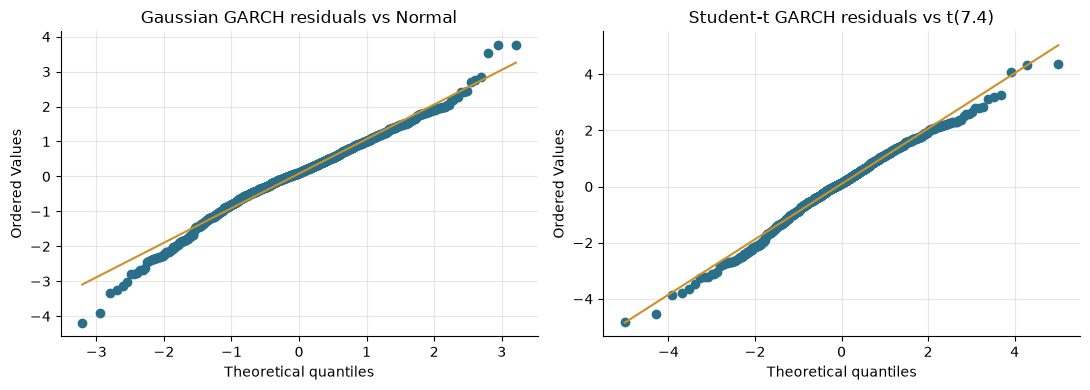

In [66]:
h_g = variance_path(*point_estimates["Full-cov VI"])
h_t = variance_path(w_t.mean(), a_t.mean(), b_t.mean())
z_g, z_t = r_all[:n_train] / np.sqrt(h_g[:n_train]), r_all[:n_train] / np.sqrt(h_t[:n_train])
nu_hat = nu_t.mean()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(z_g, dist="norm", plot=ax[0]); ax[0].set_title("Gaussian GARCH residuals vs Normal")
stats.probplot(z_t * np.sqrt(nu_hat / (nu_hat - 2)), dist=stats.t(nu_hat), plot=ax[1])
ax[1].set_title(f"Student-t GARCH residuals vs t({nu_hat:.1f})")
for a in ax: a.get_lines()[0].set_color(TEAL); a.get_lines()[1].set_color(GOLD)
plt.tight_layout(); save_fig("10_qq_gauss_vs_t"); plt.show()

**Interpretation.**
- The **ELBO is higher** for the Student-t model, so it has more Bayesian evidence. This comparison is valid because both objectives are
  genuine lower bounds on $\log p(y)$ with the same prior structure and no extra penalty terms.
- The Student-t model also has a **higher out-of-sample predictive log-likelihood**, so it forecasts the test-period return distribution better.
- Gaussian-GARCH residuals still have fat tails (the Q-Q points bend away at the ends), whereas the Student-t Q-Q plot is much closer to the line.
  GARCH removes much of the excess kurtosis by letting variance move, but not all of it.

Unlike the original notebook, this conclusion rests on a like-for-like comparison and not on a loss that included an extra penalty.

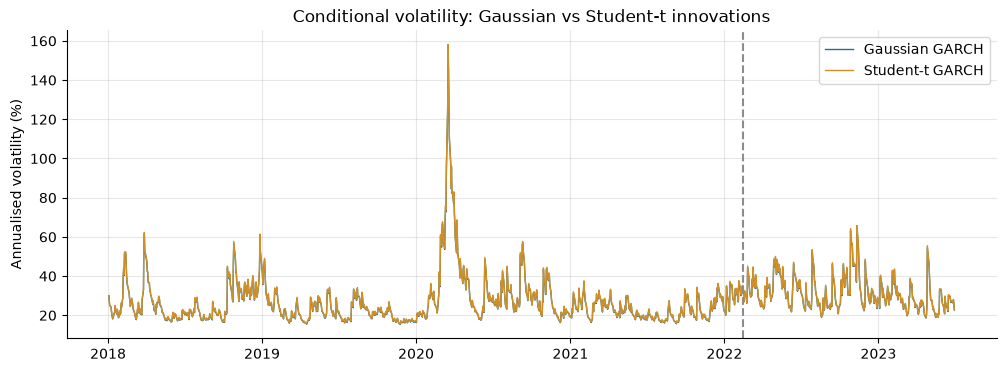

In [67]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates, np.sqrt(252 * h_g), color=TEAL, lw=1, label="Gaussian GARCH")
ax.plot(dates, np.sqrt(252 * h_t), color=GOLD, lw=1, label="Student-t GARCH")
ax.axvline(r_test.index[0], color=GREY, ls="--")
ax.set_ylabel("Annualised volatility (%)"); ax.set_title("Conditional volatility: Gaussian vs Student-t innovations"); ax.legend()
save_fig("11_vol_gauss_vs_t"); plt.show()

**Interpretation.** The two volatility paths are **almost identical**. The Student-t model does not improve the volatility *path*.
It improves the **shape of the forecast distribution**: extreme returns are assigned realistic probabilities through $\nu \approx 7$
instead of being treated as near-impossible Normal events. That is why the gain shows up in log-likelihood and model evidence
rather than in RMSE-type metrics, and it matters most for tail-risk measures such as Value-at-Risk.

## 13. Mini Large-Scale Experiment: Dow Jones 30 Stocks

The paper's headline result (Table I) comes from 488 S&P 500 stocks. As a smaller check, we repeat QML, MCMC and BBVI with **identical
hyperparameters for every stock** on the 30 Dow Jones constituents (all S&P 500 members), using the same dates and split.

Data cleaning rule (as in the paper): drop any stock with an incomplete price history over the window.

In [68]:
DOW30 = ["AAPL", "AMGN", "AXP", "BA", "CAT", "CRM", "CSCO", "CVX", "DIS", "DOW", "GS", "HD", "HON", "IBM", "INTC",
         "JNJ", "JPM", "KO", "MCD", "MMM", "MRK", "MSFT", "NKE", "PG", "TRV", "UNH", "V", "VZ", "WBA", "WMT"]

panel = pd.DataFrame({tk: load_prices(tk)["Close"] for tk in DOW30})
print(panel.shape)

/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/private/tmp/claude-501/-User

/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/private/tmp/claude-501/-User

/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/private/tmp/claude-501/-User

/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/private/tmp/claude-501/-User

/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabu

...


1 Failed download:


['WBA']: possibly delisted; no timezone found


/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/multi.py:220: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.rename(columns=ctx.isins, inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/multi.py:224: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.sort_index(level=0, axis=1, inplace=True)


/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/private/tmp/claude-501/-Users-a65911-Desktop-Fordham-Sem-2-syllabus-Time-Series-Econometrics-Project-Stuff-I-ll-Submit/d5a93af1-97e3-4605-96f4-68db8e6307ef/scratchpad/venv/lib/python3.13/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/private/tmp/claude-501/-User

(1383, 30)


In [69]:
missing = panel.isna().sum()
print("Stocks with missing prices:")
print(missing[missing > 0])

Stocks with missing prices:
DOW     304
WBA    1383
dtype: int64


In [70]:
panel = panel.loc[:, missing == 0]
panel_returns = 100 * np.log(panel).diff().dropna()
print(f"Stocks kept: {panel.shape[1]}   Return observations per stock: {len(panel_returns)}")

Stocks kept: 28   Return observations per stock: 1382


**Cleaning note.** Two stocks are excluded:
- **DOW**: Dow Inc. only started trading in March 2019 after the DowDuPont spin-off, so it has no prices for 2018.
- **WBA**: Walgreens Boots Alliance was taken private in 2025, and Yahoo Finance no longer serves its price history.

That leaves 28 stocks. This kind of survivorship issue is why the paper also drops constituents with incomplete series (488 of 500).

In [71]:
def fit_one_stock(r, seed=SEED):
    # QML, MCMC and BBVI for one return series; returns test/train metrics for each method.
    n_tr = int(0.75 * len(r)); r_tr_s = r[:n_tr]; h0 = np.mean(r_tr_s ** 2)
    loglik = lambda th: gaussian_loglik(th, r_tr_s, h0)
    log_post = lambda th: loglik(th) + log_prior(th)

    th_qml = minimize(lambda th: -loglik(th), np.zeros(3), method="Nelder-Mead",
                      options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 5000}).x
    t0 = time.perf_counter()
    mode = minimize(lambda th: -log_post(th), th_qml, method="Nelder-Mead").x
    cov = np.linalg.inv(-approx_hess(mode, log_post))
    ch, _ = random_walk_metropolis(log_post, mode, cov, N_MCMC, seed)
    t_mcmc = time.perf_counter() - t0
    t0 = time.perf_counter()
    mu, sig, _ = bbvi(log_post, seed=seed)
    t_bbvi = time.perf_counter() - t0
    th_bbvi = mu + sig * np.random.default_rng(seed).standard_normal((N_DRAWS, 3))

    out = {}
    for name, params in [("QML", to_garch(th_qml)),
                         ("MCMC", [x.mean() for x in to_garch(ch[BURN:])]),
                         ("BBVI", [x.mean() for x in to_garch(th_bbvi)])]:
        h = garch_filter(*params, r, h0)
        out[name] = {**{f"{k} train": v for k, v in metrics(h[:n_tr], r[:n_tr]).items()},
                     **{f"{k} test":  v for k, v in metrics(h[n_tr:], r[n_tr:]).items()}}
    out["time"] = {"MCMC": t_mcmc, "BBVI": t_bbvi}
    return out

In [72]:
t0 = time.perf_counter()
panel_results = {tk: fit_one_stock(panel_returns[tk].values) for tk in panel_returns.columns}
print(f"Fitted {len(panel_results)} stocks × 3 methods in {time.perf_counter() - t0:.0f}s")

Fitted 28 stocks × 3 methods in 41s


In [73]:
rows = []
for tk, res in panel_results.items():
    for method in ["MCMC", "BBVI"]:
        dev = {k: 100 * (res[method][k] / res["QML"][k] - 1) for k in res["QML"]}
        rows.append({"stock": tk, "method": method, **dev})
dev_df = pd.DataFrame(rows)

cols = ["RMSE train", "MAD train", "QLIK train", "NLL train", "RMSE test", "MAD test", "QLIK test", "NLL test"]
summary = dev_df.groupby("method")[cols].agg(["mean", "std"]).round(3)
summary.columns = [f"{c} ({s})" for c, s in summary.columns]
print("% deviation from QML, mean and std across stocks (cf. paper Table I):")
summary.T

% deviation from QML, mean and std across stocks (cf. paper Table I):


method,BBVI,MCMC
RMSE train (mean),-0.375,-0.398
RMSE train (std),0.501,0.507
MAD train (mean),-0.532,-0.228
MAD train (std),1.279,1.376
QLIK train (mean),0.125,0.129
QLIK train (std),0.127,0.127
NLL train (mean),0.059,0.061
NLL train (std),0.048,0.049
RMSE test (mean),0.313,0.356
RMSE test (std),0.452,0.459


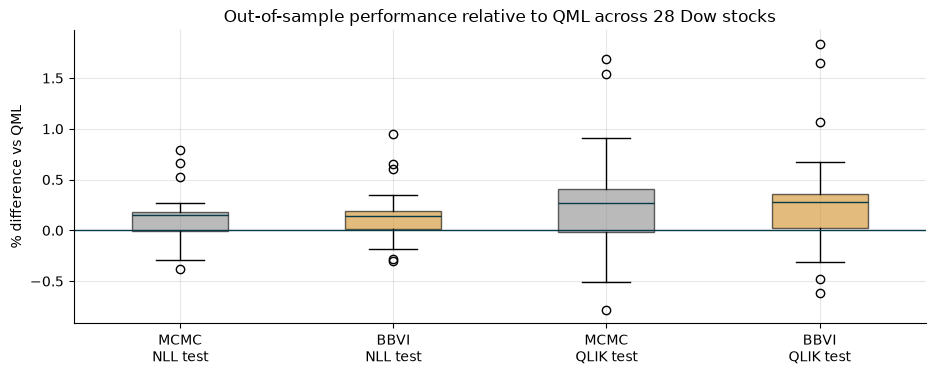

In [74]:
fig, ax = plt.subplots(figsize=(11, 3.8))
data = [dev_df.query("method == @m")["NLL test"] for m in ["MCMC", "BBVI"]] + \
       [dev_df.query("method == @m")["QLIK test"] for m in ["MCMC", "BBVI"]]
bp = ax.boxplot(data, tick_labels=["MCMC\nNLL test", "BBVI\nNLL test", "MCMC\nQLIK test", "BBVI\nQLIK test"], patch_artist=True,
                medianprops={"color": DARK})
for patch, col in zip(bp["boxes"], [GREY, GOLD, GREY, GOLD]): patch.set_facecolor(col); patch.set_alpha(0.6)
ax.axhline(0, color=DARK, lw=1); ax.set_ylabel("% difference vs QML")
ax.set_title(f"Out-of-sample performance relative to QML across {len(panel_results)} Dow stocks"); save_fig("12_panel_boxplot"); plt.show()

In [75]:
print(f"Share of stocks where QML has the lowest train NLL: {(dev_df['NLL train'] > 0).mean():.0%}")

Share of stocks where QML has the lowest train NLL: 100%


In [76]:
times = pd.DataFrame({tk: res["time"] for tk, res in panel_results.items()}).T
print("Average run time per stock (s):")
times.mean().round(2)

Average run time per stock (s):


MCMC    0.33
BBVI    1.12
dtype: float64

**Interpretation.**
- Across 28 stocks, the average deviation of MCMC and BBVI from QML is **well under 1%** on every metric (about +0.1% for test NLL and
  +0.3% for test QLIK), the same order of magnitude as the paper's Table I. Train NLL deviations are positive for every stock, because QML
  maximises the training likelihood by definition.
- The spread across stocks is largest for MAD. Squared returns are a very noisy volatility proxy, and absolute-error metrics are driven
  by a few extreme days (this is also visible in the paper's large standard deviations).
- MCMC and BBVI are almost indistinguishable from each other, so for *point* forecasts the choice of Bayesian method is secondary.
- The **same VI hyperparameters worked for every stock with no tuning**, which supports the paper's argument that VI is practical at scale.

## 14. Conclusions

1. **Replication.** Our QML, MCMC and BBVI estimates for MSFT GARCH(1,1) reproduce the paper's Table II to within about 0.02 on every parameter.
2. **Accuracy.** VI point forecasts are as good as QML and MCMC: within about 1% on out-of-sample NLL, QLIK, RMSE and MAD, both for MSFT and across 28 Dow stocks.
3. **Uncertainty.** Full-covariance Gaussian VI reproduces the MCMC posterior (means, standard deviations, the $\alpha$–$\beta$ correlation and
   volatility bands). **Diagonal BBVI is over-confident**: it understates the posterior SD of $\omega$ and $\beta$ by about 35–55%. This matches the paper.
4. **Fat tails.** Student-t innovations ($\nu \approx 7$) beat the Gaussian model on both the ELBO (+11 log-evidence units) and the out-of-sample
   log-likelihood (+12). The volatility path itself barely changes.
5. **Computation.** For a 3-parameter GARCH, MCMC is cheap and VI is *not* faster. VI's advantages are generic tuning, simple convergence monitoring,
   a reusable analytical posterior, and scalability to higher-dimensional models.

### Limitations and extensions
- One asset for the detailed case study, and 28 stocks rather than 488. Only GARCH(1,1) is studied (the paper also covers GJR, EGARCH and FIGARCH).
- Squared returns are a noisy proxy for true variance. Realised volatility from intraday data (e.g. WRDS TAQ) would sharpen RMSE/QLIK comparisons.
- Natural extensions: GJR-GARCH for leverage effects, FIGARCH for long memory, the natural-gradient optimisers (QBVI, MGVB, EMGVB),
  and multivariate GARCH, where VI's scalability advantage over MCMC should matter more.

### References
- Magris, M., & Iosifidis, A. (2023). Variational Inference for GARCH-family Models. *arXiv:2310.03435*.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Bollerslev, T. (1987). A conditionally heteroskedastic time series model for speculative prices and rates of return. *Review of Economics and Statistics*, 69(3), 542–547.
- Blei, D. M., Kucukelbir, A., & McAuliffe, J. D. (2017). Variational Inference: A Review for Statisticians. *JASA*, 112(518), 859–877.
- Ranganath, R., Gerrish, S., & Blei, D. (2014). Black Box Variational Inference. *AISTATS*.
- Kingma, D. P., & Welling, M. (2014). Auto-Encoding Variational Bayes. *ICLR* (reparameterisation trick).
- Roberts, G. O., Gelman, A., & Gilks, W. R. (1997). Weak convergence and optimal scaling of random walk Metropolis algorithms. *Annals of Applied Probability*, 7(1), 110–120.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.